In [1]:
import numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
data_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images")
labels_dir = data_dir / "labels"
images_dir = data_dir / "rare_granules"
model_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3")

In [3]:
labels_dict = {
    1: "granule",
    2: "tail",
    3: "spike"
}

In [4]:
import json
from pathlib import Path

with open(model_dir / "pixel_feature_row_ranges.json", "r") as f:
    row_ranges = json.load(f)

for key, item in row_ranges.items():
    print(key, item)

print(len(row_ranges))

40135_E1_x4300_-10um_0013.png {'start': 0, 'end': 6879154}
40135_G1_x4300_-10um_0002.png {'start': 6879154, 'end': 8986558}
40135_G1_x4300_-10um_0101.png {'start': 8986558, 'end': 10870127}
40135_E4_new_x4300_-10um_0053.png {'start': 10870127, 'end': 14828627}
40135_G1_x4300_-10um_0095.png {'start': 14828627, 'end': 20955057}
40135_E4_new_x4300_-10um_0023.png {'start': 20955057, 'end': 24096305}
40135_G1_x4300_-10um_0093.png {'start': 24096305, 'end': 27227089}
40135_E4_new_x4300_-10um_0064.png {'start': 27227089, 'end': 30840754}
40135_E4_new_x4300_-10um_0021.png {'start': 30840754, 'end': 32934658}
40135-B5_x4300_-10um_0025.png {'start': 32934658, 'end': 36604733}
40135_G1_x4300_-10um_0024.png {'start': 36604733, 'end': 38205817}
40135_E4_new_x4300_-10um_0029.png {'start': 38205817, 'end': 42026569}
40135_G1_x4300_-10um_0091.png {'start': 42026569, 'end': 48105511}
40135_E4_new_x4300_-10um_0097.png {'start': 48105511, 'end': 51684541}
40135_E4_new_x4300_-10um_0027.png {'start': 51684

In [5]:
all_data = np.load(model_dir / "pixel_features.npy")

In [6]:
all_data.shape, np.unique(all_data[:, -1], return_counts=True)

((67931949, 20),
 (array([0., 1., 2., 3.], dtype=float32),
  array([67655535,   150770,    98775,    26869])))

In [7]:
import numpy as np


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

label_col = -1
background_ratio = 4
random_seed = 42

rng = np.random.default_rng(random_seed)


# ------------------------------------------------------------
# CONVERT LABEL 1 -> 0 (if still present)
# ------------------------------------------------------------

# labels = all_data[:, label_col]

# labels[labels == 1] = 0


# ------------------------------------------------------------
# FIND PIXELS BY CLASS
# ------------------------------------------------------------

class1_indices = np.flatnonzero(
    all_data[:, label_col] == 1
)

class2_indices = np.flatnonzero(
    all_data[:, label_col] == 2
)

class3_indices = np.flatnonzero(
    all_data[:, label_col] == 3
)

background_indices = np.flatnonzero(
    all_data[:, label_col] == 0
)


print("Available pixels:")
print("Class 0:", len(background_indices))
print("Class 1:", len(class1_indices))
print("Class 2:", len(class2_indices))
print("Class 3:", len(class3_indices))


# ------------------------------------------------------------
# SAMPLE BACKGROUND
# ------------------------------------------------------------

n_foreground = len(class1_indices) + len(class2_indices) + len(class3_indices)

n_background = min(
    n_foreground * background_ratio,
    len(background_indices),
)

sampled_background_indices = rng.choice(
    background_indices,
    size=n_background,
    replace=False,
)


# ------------------------------------------------------------
# COMBINE TRAINING INDICES
# ------------------------------------------------------------

train_indices = np.concatenate([
    class1_indices,
    class2_indices,
    class3_indices,
    sampled_background_indices,
])

# Shuffle pixels
rng.shuffle(train_indices)


# ------------------------------------------------------------
# CREATE TRAINING DATA
# ------------------------------------------------------------

train_data = all_data[train_indices]

X_train = train_data[:, :-1]
y_train = train_data[:, -1].astype(np.uint8)


# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

print("\nTraining shape:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTraining label counts:")
labels, counts = np.unique(y_train, return_counts=True)

for label, count in zip(labels, counts):
    print(label, f"{count:,}")

Available pixels:
Class 0: 67655535
Class 1: 150770
Class 2: 98775
Class 3: 26869

Training shape:
X_train: (1382070, 19)
y_train: (1382070,)

Training label counts:
0 1,105,656
1 150,770
2 98,775
3 26,869


In [8]:
import joblib

from sklearn.ensemble import RandomForestClassifier


# ------------------------------------------------------------
# TRAIN RANDOM FOREST
# ------------------------------------------------------------

# rf = RandomForestClassifier(
#     n_estimators=300,
#     class_weight="balanced_subsample",
#     n_jobs=-1,
#     random_state=42,
#     verbose=1,
# )

# rf.fit(X_train, y_train)




In [16]:
arr = np.array([1,1,0,0,2,2,3,0,0])
np.where(arr)[0]

array([0, 1, 4, 5, 6])

In [17]:
rf = RandomForestClassifier(
    n_estimators=50,
    warm_start=True,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
)

scores = []
y_nonzero = np.where(y_train)[0]
y_nonzero_vals = y_train[y_nonzero]

for n_trees in [50, 100, 150, 200, 300, 500]:
    rf.set_params(n_estimators=n_trees)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_train)
    y_pred_nonzero = y_pred[y_nonzero]

    scores.append(np.count_nonzero(y_pred_nonzero == y_nonzero_vals) / len(y_nonzero_vals))

    # Calculate whatever metrics you care about here

/home/xgupke/miniforge3/envs/elin/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(
/home/xgupke/miniforge3/envs/elin/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:843: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency dis

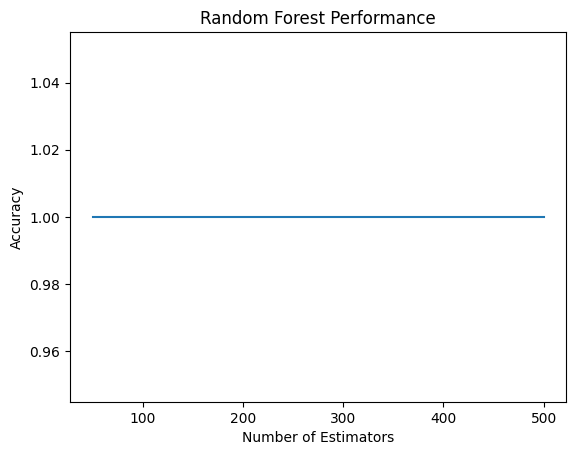

In [18]:
from matplotlib import pyplot as plt

plt.plot([50, 100, 150, 200, 300, 500], scores)
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.title("Random Forest Performance")
plt.show()

In [19]:
y_pred_nonzero, y_nonzero_vals

(array([1, 2, 3, ..., 2, 1, 3], shape=(276414,), dtype=uint8),
 array([1, 2, 3, ..., 2, 1, 3], shape=(276414,), dtype=uint8))

In [11]:
scores

[np.float64(0.9999978293429421),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0)]

In [ ]:
# ------------------------------------------------------------
# SAVE MODEL
# ------------------------------------------------------------

model_path = model_dir / "random_forest_px.joblib"

joblib.dump(rf, model_path)

print(f"Saved model to: {model_path}")

In [ ]:
# """
# The original code which split into train and test. Not needed if we already have a test set, and if the feature map was calculated on the train images only.
# """

# # ------------------------------------------------------------
# # SETTINGS
# # ------------------------------------------------------------

# label_col = -1

# test_fraction = 0.20
# random_seed = 42

# # Training background sampling
# background_ratio = 4
# min_background_per_image = 20_000
# max_background_per_image = 100_000

# # How many test images containing class 3 you would ideally like
# n_class3_test = 2

# rng = np.random.default_rng(random_seed)


# # ------------------------------------------------------------
# # 1. CHANGE LABEL 1 -> 0
# # ------------------------------------------------------------
# # Do this in chunks so we don't create a gigantic 70-million-element
# # boolean mask all at once.

# chunk_size = 5_000_000

# for start in range(0, len(all_data), chunk_size):
#     end = min(start + chunk_size, len(all_data))

#     labels = all_data[start:end, label_col]
#     labels[labels == 1] = 0


# # ------------------------------------------------------------
# # 2. COUNT CLASSES IN EACH IMAGE
# # ------------------------------------------------------------

# image_info = {}

# for img_name, bounds in row_ranges.items():
#     start = bounds["start"]
#     end = bounds["end"]

#     labels = all_data[start:end, label_col]

#     image_info[img_name] = {
#         0: np.count_nonzero(labels == 0),
#         2: np.count_nonzero(labels == 2),
#         3: np.count_nonzero(labels == 3),
#     }


# print("\nClass counts by image:\n")

# for img_name, counts in image_info.items():
#     print(
#         img_name,
#         f"background={counts[0]:,}",
#         f"class2={counts[2]:,}",
#         f"class3={counts[3]:,}",
#     )


# # ------------------------------------------------------------
# # 3. SELECT TEST IMAGES
# # ------------------------------------------------------------

# from itertools import combinations

# all_images = list(row_ranges.keys())

# max_test_images = 4
# n_spike_test = 2

# valid_splits = []

# # Try every combination of 4 images
# for combo in combinations(all_images, max_test_images):

#     spike_count = sum(
#         image_info[img][3] > 0
#         for img in combo
#     )

#     tail_count = sum(
#         image_info[img][2] > 0
#         for img in combo
#     )

#     # Require exactly 2 spike-containing images
#     if spike_count != n_spike_test:
#         continue

#     # Store candidate
#     valid_splits.append({
#         "images": combo,
#         "tail_cases": tail_count,

#         # Number of actual foreground pixels going into test
#         "tail_pixels": sum(image_info[img][2] for img in combo),
#         "spike_pixels": sum(image_info[img][3] for img in combo),
#     })


# if not valid_splits:
#     raise ValueError(
#         "Could not find a 4-image test set containing exactly 2 spike cases."
#     )


# # ------------------------------------------------------------
# # Choose the split
# #
# # Priority:
# # 1. As many tail-containing cases as possible
# # 2. Among those, use fewer foreground pixels for test
# #    so more annotated pixels remain available for training
# # ------------------------------------------------------------

# valid_splits.sort(
#     key=lambda x: (
#         -x["tail_cases"],
#         x["tail_pixels"] + x["spike_pixels"],
#     )
# )

# best_split = valid_splits[0]

# test_images = list(best_split["images"])

# train_images = [
#     img for img in all_images
#     if img not in test_images
# ]


# # ------------------------------------------------------------
# # CHECK SPLIT
# # ------------------------------------------------------------

# n_spike_cases_test = sum(
#     image_info[img][3] > 0
#     for img in test_images
# )

# n_tail_cases_test = sum(
#     image_info[img][2] > 0
#     for img in test_images
# )


# print("\nTEST IMAGES:")

# for img in test_images:
#     print(img, image_info[img])


# print("\nTest spike cases:", n_spike_cases_test)
# print("Test tail cases:", n_tail_cases_test)

# print("Train spike cases:",
#       sum(image_info[img][3] > 0 for img in train_images))

# print("Train tail cases:",
#       sum(image_info[img][2] > 0 for img in train_images))

# print("\nNumber train images:", len(train_images))
# print("Number test images:", len(test_images))


# assert len(test_images) <= 4
# assert n_spike_cases_test == 2


# # ------------------------------------------------------------
# # 4. SAMPLE TRAINING PIXELS
# # ------------------------------------------------------------

# train_indices = []


# for img_name in train_images:

#     start = row_ranges[img_name]["start"]
#     end = row_ranges[img_name]["end"]

#     labels = all_data[start:end, label_col]

#     # Local indices within this image
#     class2_local = np.flatnonzero(labels == 2)
#     class3_local = np.flatnonzero(labels == 3)
#     background_local = np.flatnonzero(labels == 0)

#     # Keep ALL foreground pixels
#     foreground_local = np.concatenate([
#         class2_local,
#         class3_local,
#     ])

#     n_foreground = len(foreground_local)

#     # Background amount depends on amount of foreground,
#     # but is bounded so one image cannot dominate.
#     n_background = n_foreground * background_ratio

#     n_background = max(
#         n_background,
#         min_background_per_image,
#     )

#     n_background = min(
#         n_background,
#         max_background_per_image,
#         len(background_local),
#     )

#     if n_background > 0:
#         sampled_background = rng.choice(
#             background_local,
#             size=n_background,
#             replace=False,
#         )
#     else:
#         sampled_background = np.array([], dtype=np.int64)

#     local_indices = np.concatenate([
#         foreground_local,
#         sampled_background,
#     ])

#     # Convert image-local indices to indices in all_data
#     global_indices = local_indices + start

#     train_indices.append(global_indices)


# train_indices = np.concatenate(train_indices)

# # Shuffle training pixels
# rng.shuffle(train_indices)


# # ------------------------------------------------------------
# # 5. TEST INDICES
# # ------------------------------------------------------------
# # Keep COMPLETE test images.
# #
# # This preserves the real background/foreground distribution,
# # which is what you want when evaluating the classifier.

# test_indices = []

# for img_name in test_images:
#     start = row_ranges[img_name]["start"]
#     end = row_ranges[img_name]["end"]

#     test_indices.append(
#         np.arange(start, end, dtype=np.int64)
#     )

# test_indices = np.concatenate(test_indices)


# # ------------------------------------------------------------
# # 6. CREATE TRAIN / TEST ARRAYS
# # ------------------------------------------------------------

# train_data = all_data[train_indices]
# test_data = all_data[test_indices]

# X_train = train_data[:, :-1]
# y_train = train_data[:, -1].astype(np.uint8)

# X_test = test_data[:, :-1]
# y_test = test_data[:, -1].astype(np.uint8)


# print("\nFINAL DATA:")
# print("X_train:", X_train.shape)
# print("y_train:", y_train.shape)

# print("X_test:", X_test.shape)
# print("y_test:", y_test.shape)


# print("\nTRAIN LABEL COUNTS:")
# labels, counts = np.unique(y_train, return_counts=True)
# for label, count in zip(labels, counts):
#     print(label, f"{count:,}")


# print("\nTEST LABEL COUNTS:")
# labels, counts = np.unique(y_test, return_counts=True)
# for label, count in zip(labels, counts):
#     print(label, f"{count:,}")

In [ ]:
# # ------------------------------------------------------------
# # 3. SELECT TEST IMAGES
# # ------------------------------------------------------------

# all_images = list(row_ranges.keys())

# n_test = max(5, round(len(all_images) * test_fraction))

# # Images containing both foreground classes
# both_classes = [
#     img for img in all_images
#     if image_info[img][2] > 0 and image_info[img][3] > 0
# ]

# # Images containing class 3
# class3_images = [
#     img for img in all_images
#     if image_info[img][3] > 0
# ]

# test_images = []


# # First: include one image containing BOTH classes if possible
# if both_classes:
#     chosen = rng.choice(both_classes)
#     test_images.append(chosen)


# # Second: make sure we have up to n_class3_test class-3 images
# remaining_class3 = [
#     img for img in class3_images
#     if img not in test_images
# ]

# n_needed = min(
#     n_class3_test - sum(img in class3_images for img in test_images),
#     len(remaining_class3),
# )

# if n_needed > 0:
#     chosen = rng.choice(
#         remaining_class3,
#         size=n_needed,
#         replace=False,
#     )

#     test_images.extend(np.atleast_1d(chosen).tolist())


# # Make sure at least 5 test images contain tails (class 2)
# tail_images = [
#     img for img in all_images
#     if image_info[img][2] > 0
# ]

# n_tail_test = 3

# current_tail_count = sum(
#     img in tail_images for img in test_images
# )

# remaining_tail_images = [
#     img for img in tail_images
#     if img not in test_images
# ]

# n_needed = min(
#     n_tail_test - current_tail_count,
#     len(remaining_tail_images),
# )

# if n_needed > 0:
#     chosen = rng.choice(
#         remaining_tail_images,
#         size=n_needed,
#         replace=False,
#     )

#     test_images.extend(np.atleast_1d(chosen).tolist())


# # Fill the rest of the test set randomly
# remaining_images = [
#     img for img in all_images
#     if img not in test_images
# ]

# n_remaining = n_test - len(test_images)

# if n_remaining > 0:
#     chosen = rng.choice(
#         remaining_images,
#         size=min(n_remaining, len(remaining_images)),
#         replace=False,
#     )

#     test_images.extend(np.atleast_1d(chosen).tolist())


# train_images = [
#     img for img in all_images
#     if img not in test_images
# ]

# n_spike_test = sum(image_info[img][3] > 0 for img in test_images)
# n_tail_test = sum(image_info[img][2] > 0 for img in test_images)

# print(f"\nSpike-containing test images: {n_spike_test}")
# print(f"Tail-containing test images: {n_tail_test}")

# assert n_spike_test >= n_class3_test, (
#     f"Only {n_spike_test} spike-containing test images were selected."
# )

# assert n_tail_test >= n_tail_test, (
#     f"Only {n_tail_test} tail-containing test images were selected."
# )


# print("\nTEST IMAGES:")
# for img in test_images:
#     print(img, image_info[img])

# print("\nNumber train images:", len(train_images))
# print("Number test images:", len(test_images))